# 04 Distributions of the key variables


In [1]:
from common import *
from scipy import stats
b = pd.read_parquet(OUT / "base_table.parquet")
s = b[b.region.isin(SCORED)]
V = ["land_km2", "housing_units", "pop_total", "bldg_n", "road_km_hwy", "road_km_all", "poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school", "poi_n_hospital", "rail_km", "infra_n"]
def desc(x):
    x = x.dropna()
    return pd.Series(dict(zero_share=(x == 0).mean(), mean=x.mean(), median=x.median(), p90=x.quantile(.9), p99=x.quantile(.99), max=x.max(),
                          skew=stats.skew(x), skew_log1p=stats.skew(np.log1p(x))))
print(s[V].apply(desc).T.to_string())

                zero_share      mean    median       p90        p99        max   skew  skew_log1p
land_km2             0.000    99.929     3.832   199.165  1,924.045  8,892.508  9.297       1.370
housing_units        0.009 1,748.215 1,646.000 2,687.200  4,305.100 13,827.000  1.974      -6.051
pop_total            0.003 4,131.615 3,907.000 6,416.000 10,037.420 30,199.000  1.707      -6.131
bldg_n               0.000 1,928.611 1,698.000 3,459.800  5,960.660 16,723.000  1.754      -1.587
road_km_hwy          0.014    19.241     7.781    47.236    187.277    482.534  5.062       0.500
road_km_all          0.000   105.616    36.694   249.256  1,127.494  4,696.879  6.697       0.766
poi_n                0.000   205.215   142.000   423.000  1,094.880  5,236.000  5.722      -0.215
poi_n_fire           0.707     0.369     0.000     1.000      3.000      6.000  2.184       1.292
poi_n_ems            0.928     0.085     0.000     0.000      2.000      5.000  4.782       3.686
poi_n_school        

## 1. Shapes, raw and log scale
Histograms of the six variables the project models: raw on the top row, log1p below.

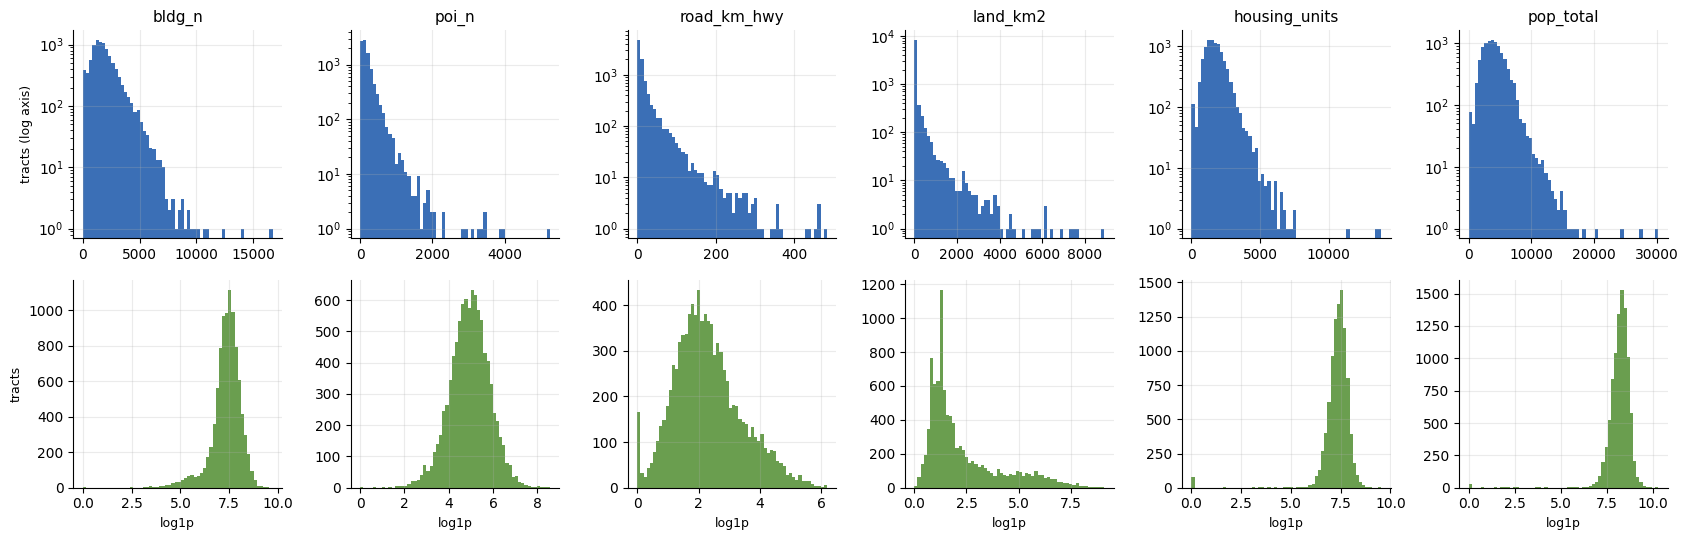

In [2]:
M = ["bldg_n", "poi_n", "road_km_hwy", "land_km2", "housing_units", "pop_total"]
fig, ax = plt.subplots(2, 6, figsize=(17, 5.5))
for j, v in enumerate(M):
    ax[0, j].hist(s[v], bins=60, color="#3b6fb6"); ax[0, j].set_title(v); ax[0, j].set_yscale("log")
    ax[1, j].hist(np.log1p(s[v]), bins=60, color="#6a9e4f"); ax[1, j].set_xlabel("log1p")
ax[0, 0].set_ylabel("tracts (log axis)"); ax[1, 0].set_ylabel("tracts")
plt.show()

## 2. Zeros and rare categories
Fire, EMS and school places, and highway-class roads, are zero in many tracts. Count how common zero is per region, since this is where a Poisson model would fit badly and where a "no reference to compare" case would arise in the hidden target.

In [3]:
Z = ["bldg_n", "road_km_hwy", "poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school", "poi_n_hospital", "rail_km", "infra_n"]
z = b.groupby("region")[Z].agg(lambda x: (x == 0).mean()).loc[REG]
print("share of tracts with zero:"); print(z.round(3).T.to_string())
print("\nmean count where nonzero:"); print(b.groupby("region")[["poi_n_fire", "poi_n_ems", "poi_n_school"]].agg(lambda x: x[x > 0].mean()).loc[REG].round(2).to_string())

share of tracts with zero:
region          maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
bldg_n                0.000        0.000       0.000             0.000       0.000
road_km_hwy           0.021        0.012       0.023             0.011       0.012
poi_n                 0.000        0.000       0.000             0.000       0.000
poi_n_fire            0.766        0.641       0.638             0.712       0.672
poi_n_ems             0.959        0.949       0.914             0.920       0.908
poi_n_school          0.261        0.152       0.195             0.215       0.171
poi_n_hospital        0.768        0.751       0.725             0.754       0.783
rail_km               0.761        0.528       0.431             0.596       0.376
infra_n               0.296        0.266       0.512             0.594       0.190

mean count where nonzero:
                  poi_n_fire  poi_n_ems  poi_n_school
region                                               
maricopa

**Takeaway:** Across the four scored regions, 71% of tracts have no fire-department place, 93% no EMS place, 75% no hospital and 22% no school, against only 1.4% with no highway-class road; rail is absent from 60% and infrastructure from 51%. Where fire or EMS places exist the average is 1.1 to 1.4, so these behave like presence or absence. Fire has zero in 64% (Northern CA, Eastern OK) to 77% (Maricopa) of tracts and EMS in 91% to 96%.

## 3. Over-dispersion
 Variance over mean, computed within region and within a land-area band (so size differences do not dominate), shows how far counts exceed that.

In [4]:
band = pd.qcut(s.land_km2, 5, labels=False, duplicates="drop")
rows = []
for v in ["bldg_n", "poi_n", "poi_n_fire", "poi_n_ems", "poi_n_school"]:
    g = s.groupby([s.region, band])[v].agg(["mean", "var"]); g = g[g["mean"] > 0]
    rows.append(dict(variable=v, median_var_over_mean=(g["var"] / g["mean"]).median(), min=(g["var"] / g["mean"]).min(), max=(g["var"] / g["mean"]).max()))
print(pd.DataFrame(rows).set_index("variable").round(1).to_string())
print("\nland-area band edges (km2):", [round(x, 1) for x in s.land_km2.quantile([0, .2, .4, .6, .8, 1])])

              median_var_over_mean     min       max
variable                                            
bldg_n                     258.100 102.700 1,040.900
poi_n                      214.400  55.600   649.100
poi_n_fire                   1.000   0.900     1.400
poi_n_ems                    1.200   0.900     2.200
poi_n_school                 2.100   1.200     2.900

land-area band edges (km2): [0.0, 1.7, 2.8, 5.8, 35.6, 8892.5]


**Takeaway:** Within a land-area band, building counts have a variance about 258 times their mean (median over bands) and place counts about 214 times, far beyond a Poisson count. Part of that is size variation not yet explained by housing and population, which a model will absorb, so the true over-dispersion is smaller; the facility counts are close to Poisson (variance over mean 1.0 for fire, 1.2 for EMS, 2.1 for schools).

## 4. Concentration and extremes
How much of the total sits in the largest tracts, and how many tracts are extreme outliers on the log scale.

In [5]:
rows = []
for v in ["bldg_n", "poi_n", "road_km_hwy", "land_km2", "pop_total"]:
    x = s[v].sort_values(ascending=False); top1 = int(len(x) * .01)
    lx = np.log1p(s[v]); q1, q3 = lx.quantile([.25, .75]); iqr = q3 - q1
    rows.append(dict(variable=v, top1pct_share_of_total=x.iloc[:top1].sum() / x.sum(), outliers_hi_3iqr=int((lx > q3 + 3 * iqr).sum()), outliers_lo_3iqr=int((lx < q1 - 3 * iqr).sum())))
print(pd.DataFrame(rows).set_index("variable").round(3).to_string())
print("\nlargest tracts by land area:"); print(s.nlargest(5, "land_km2")[["GEOID", "region", "land_km2", "pop_total", "bldg_n", "poi_n"]].to_string(index=False))
print("\nmost buildings:"); print(s.nlargest(3, "bldg_n")[["GEOID", "region", "land_km2", "bldg_n", "housing_units"]].to_string(index=False))

             top1pct_share_of_total  outliers_hi_3iqr  outliers_lo_3iqr
variable                                                               
bldg_n                        0.037                 0               109
poi_n                         0.079                 0                 4
road_km_hwy                   0.134                 0                 0
land_km2                      0.335                10                 0
pop_total                     0.030                 0                77

largest tracts by land area:
      GEOID           region  land_km2  pop_total    bldg_n   poi_n
35023970000      maricopa-az 8,892.508       1912 2,965.000 198.000
48465950802 south-central-tx 7,706.250       1933 5,279.000 325.000
06035040100      northern-ca 7,529.616       1627 3,072.000 108.000
48105950100 south-central-tx 7,270.935       3098 4,385.000 229.000
04005001500      maricopa-az 6,917.354       3528 9,135.000 336.000

most buildings:
      GEOID           region  land_km2   

**Takeaway:** The largest 1% of tracts hold 33.5% of all land but only 3.0% of population and 3.7% of buildings, so land area is the one heavy-tailed size variable. Ten tracts are extreme high outliers in land area, while 109 are extreme low outliers in buildings and 77 in population (tiny or near-empty tracts). The largest tract, the New Mexico bootheel tract `35023970000`, covers 8,893 km2 with 1,912 residents.

## 5. Regions side by side
Medians (not means, because of the skew) per region, including Eastern WA.

region               maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
land_km2                   2.714        4.773      10.221             3.704      10.667
housing_units          1,780.000    1,720.000   1,421.500         1,655.000   1,640.000
pop_total              4,065.000    4,058.000   3,133.500         4,013.000   3,778.000
bldg_n                 1,646.000    1,810.000   1,939.500         1,659.000   2,335.000
bldg_per_hu                0.981        1.055       1.340             1.043       1.412
road_km_hwy                5.529        7.654       8.909             8.371      11.700
road_hwy_km_per_km2        1.470        0.999       0.566             1.685       0.660
poi_n                    120.000      134.000     128.000           151.000     129.000
poi_per_bldg               0.074        0.064       0.066             0.086       0.051
poi_n_fire                 0.000        0.000       0.000             0.000       0.000
bldg_cover_share           0.156

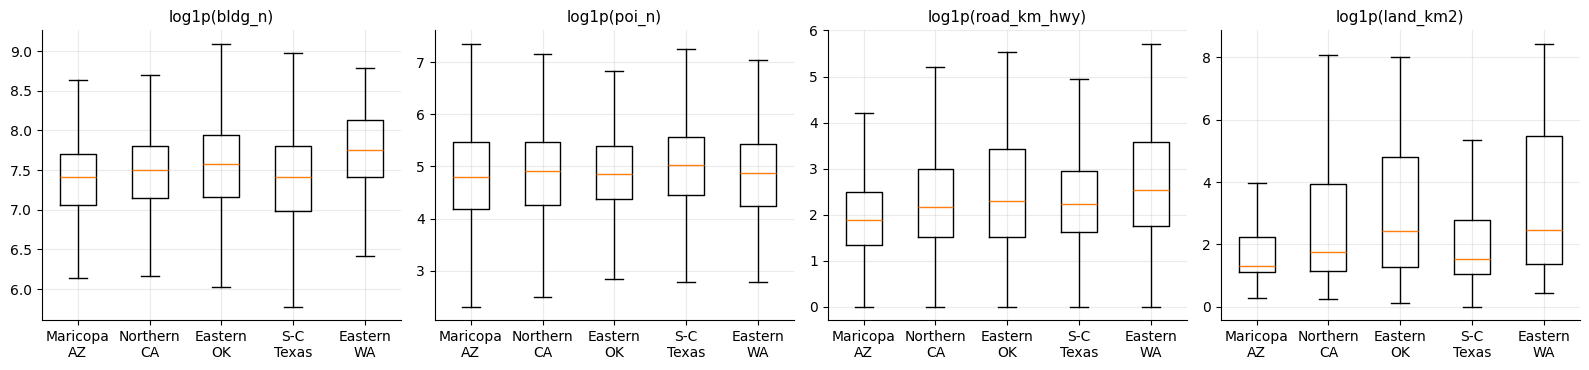

In [6]:
P = ["land_km2", "housing_units", "pop_total", "bldg_n", "bldg_per_hu", "road_km_hwy", "road_hwy_km_per_km2", "poi_n", "poi_per_bldg", "poi_n_fire", "bldg_cover_share"]
print(b.groupby("region")[P].median().loc[REG].round(3).T.to_string())
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, v in zip(ax, ["bldg_n", "poi_n", "road_km_hwy", "land_km2"]):
    a.boxplot([np.log1p(b[b.region == r][v]) for r in REG], labels=[NAME[r].split()[0] + "\n" + NAME[r].split()[-1] for r in REG], showfliers=False); a.set_title(f"log1p({v})")
plt.show()

**Takeaway:** Regions differ in level, not just spread. The median tract is 2.7 km2 in Maricopa and 3.7 km2 in Texas against 10.2 km2 in Eastern OK and 10.7 km2 in Eastern WA. Buildings per housing unit run from 0.98 (Maricopa) to 1.34 (Eastern OK) and 1.41 (Eastern WA), highway km per km2 from 0.57 (Eastern OK) to 1.69 (Texas), and footprint cover from 4.7% of land (Eastern WA) to 15.6% (Maricopa). Any pooled comparison therefore needs region as a baseline.